# 1. Power market trends and volatility

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/energy-trading/ppa-pricing-market-analyzer/notebooks/01_market_trends_and_volatility.ipynb)

Hourly day-ahead prices for a German-style market from 2019 to October 2026. The data is simulated with a simple merit-order model (gas, carbon, demand, growing solar and wind), so the patterns are realistic but the numbers are not exchange data.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "energy-trading/ppa-pricing-market-analyzer"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlsxwriter"], check=True)
else:
    here = Path.cwd()
    while not (here / "src" / "ppalab").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: ppa-pricing-market-analyzer


In [2]:
from ppalab import market as M, trends as T, pricing as P, bess as B, crm as C
d = M.load()
h = T.enrich(d["hourly"])
print(len(h), "hours from", h.timestamp.min().date(), "to", h.timestamp.max().date())

68664 hours from 2019-01-01 to 2026-10-31


In [3]:
T.yearly(h)[["year", "base", "peak", "peak_base_spread", "daily_vol", "intraday_spread", "negative_hours", "solar_capture_rate", "wind_capture_rate"]].round(2)

,year,base,peak,peak_base_spread,daily_vol,intraday_spread,negative_hours,solar_capture_rate,wind_capture_rate
0,2019,42.52,51.79,9.27,7.46,38.47,15,0.91,0.92
1,2020,40.46,46.39,5.93,6.24,34.16,16,0.89,0.95
2,2021,101.18,118.42,17.24,23.27,93.63,9,0.80,0.90
3,2022,202.98,236.71,33.74,63.51,237.60,63,0.71,0.79
4,2023,112.49,123.13,10.64,23.44,104.90,89,0.71,0.91
5,2024,71.82,72.27,0.45,12.45,65.49,197,0.70,0.92
6,2025,70.91,70.55,-0.37,15.02,73.53,373,0.63,0.91
7,2026,73.51,72.02,-1.49,17.07,85.59,366,0.59,0.87


Three things stand out: the 2022 crisis, the peak-base spread collapsing as solar covers the working-day peak hours, and solar earning less and less of the base price. Negative hours climb from a handful to several hundred a year.

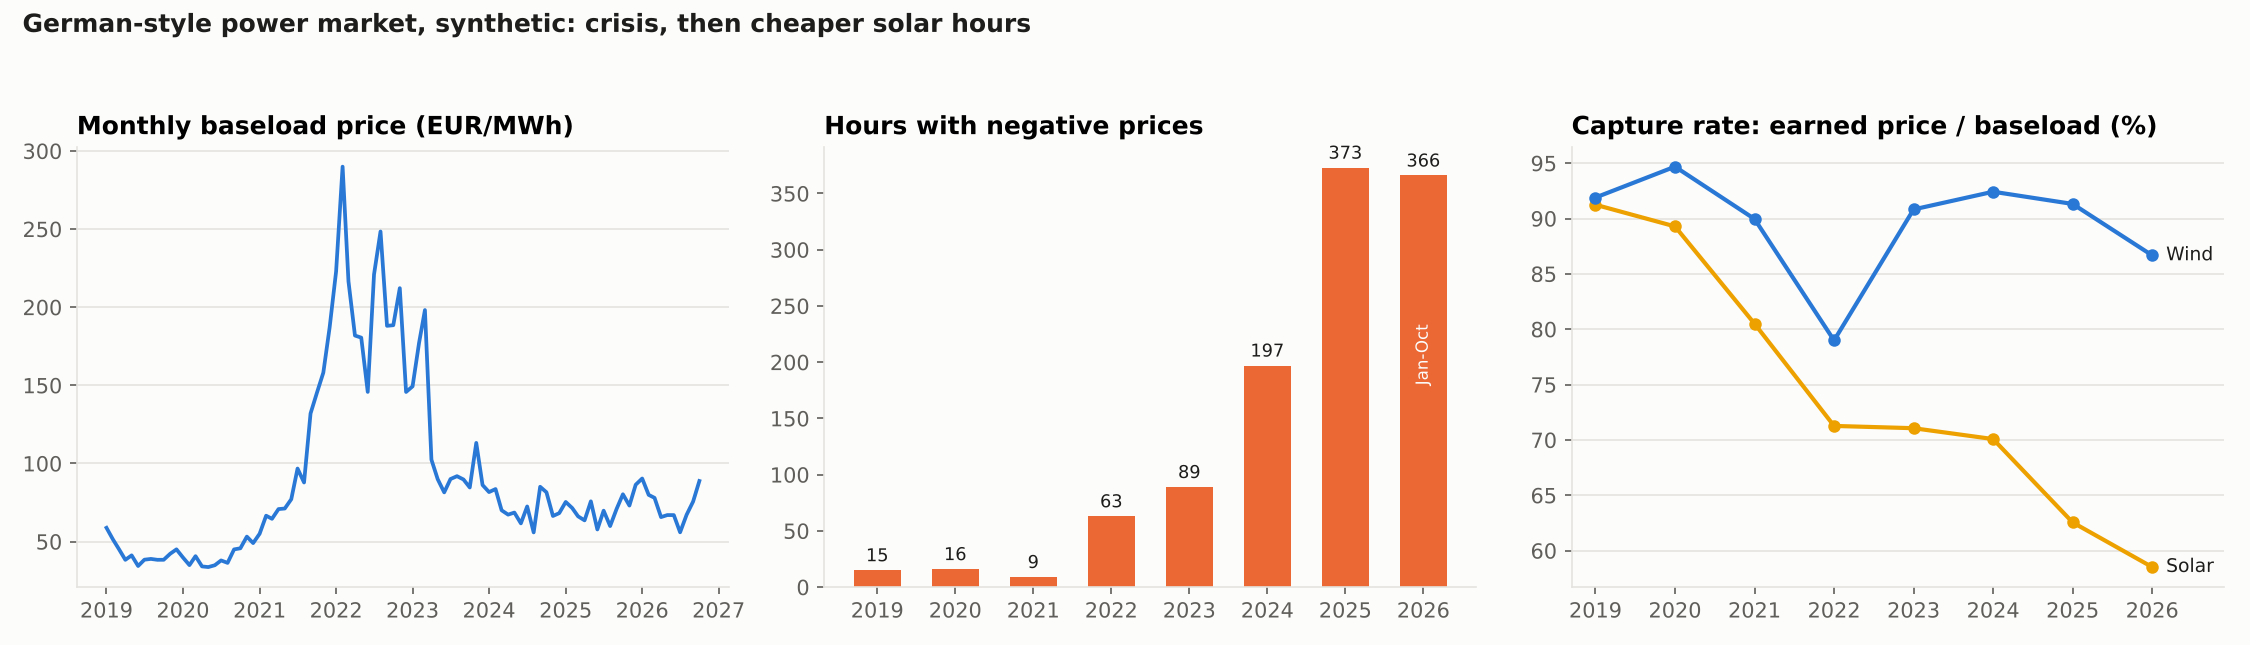

In [4]:
display(Image("outputs/figures/market_trends.png"))

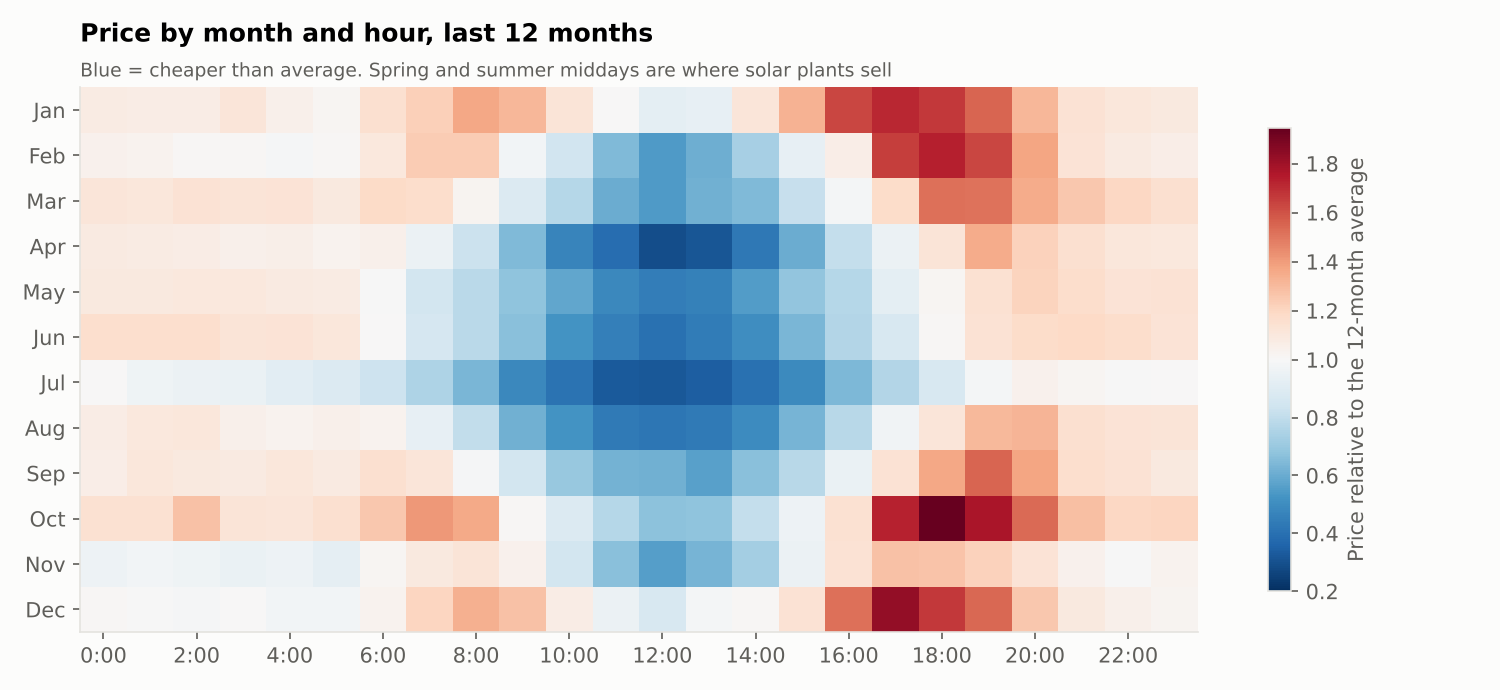

In [5]:
display(Image("outputs/figures/price_heatmap.png"))

## Forward market volatility

The Cal-27 baseload contract's annualised volatility over rolling 60-day windows. This number drives the price-level uncertainty in the PPA Monte Carlo.

In [6]:
v = T.forward_volatility(d["cal27"])
print(d["curve"])
v.annualised_vol.describe().round(3)

  product  year  base_eur_mwh  peak_eur_mwh
0  Cal-27  2027         72.33         73.04
1  Cal-28  2028         69.34         70.02
2  Cal-29  2029         67.11         67.77
3  Cal-30  2030         65.62         66.26


count    680.000
mean       0.306
std        0.018
min        0.270
25%        0.293
50%        0.305
75%        0.318
max        0.352
Name: annualised_vol, dtype: float64